# 01 - Filtrado y balanceo de datos

## Objetivo

Filtrar y balancear las imágenes HAM10000 para conservar melanomas y lunares benignos.

## Dataset elegido: HAM10000


## 1. Importación de librerías y carga del dataset

Para esto importo la libreria pandas, y defino la ruta del dataset. Una vez que esta definido compruebo la cantidad de muestras que este tiene

In [11]:

import pandas as pd
import matplotlib.pyplot as plt


#Primero defino la ruta del dataset y luego lo leo con pandas
ruta = '../data/raw/HAM10000_metadata.csv'
df = pd.read_csv(ruta)


print('Cantidad de registros de la muestra:', len(df))


Cantidad de registros de la muestra: 10015


## 2. Tipos de variables y estructura del dataset

En esta sección se observa la cantidad de filas y columnas, los nombres de las variables y el tipo de dato de cada columna.

In [12]:
# Estructura del dataset
print("El dataset tiene la cantidad de filas y columnas:", df.shape)

print("\n=== TIPOS DE DATOS Y VARIABLES ===")
df.info()


resumen_tipos = pd.DataFrame(
    {
        "Tipo de dato (Pandas)": df.dtypes.astype(str),
        "Valores faltantes": df.isna().sum(),
    }
)

display(resumen_tipos)


El dataset tiene la cantidad de filas y columnas: (10015, 7)

=== TIPOS DE DATOS Y VARIABLES ===
<class 'pandas.DataFrame'>
RangeIndex: 10015 entries, 0 to 10014
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   lesion_id     10015 non-null  str    
 1   image_id      10015 non-null  str    
 2   dx            10015 non-null  str    
 3   dx_type       10015 non-null  str    
 4   age           9958 non-null   float64
 5   sex           10015 non-null  str    
 6   localization  10015 non-null  str    
dtypes: float64(1), str(6)
memory usage: 547.8 KB


,Tipo de dato (Pandas),Valores faltantes
lesion_id,str,0
image_id,str,0
dx,str,0
dx_type,str,0
age,float64,57
sex,str,0
localization,str,0


Podemos ver que la unica variable que contiene valores faltantes es la edad de los pacientes.

## 3. Filtro de datos

Como ya se comento en el README, este data set, contiene multiples lesiones cutaneas. Sin embargo nosotros solo necesitamos las imagenes que estan referidas a lunares benignos y a melanomas.

Imagenes totales: 10015
Imagenes utiles (melanoma + lunar benigno): 7818
Imagenes no utilizadas: 2197


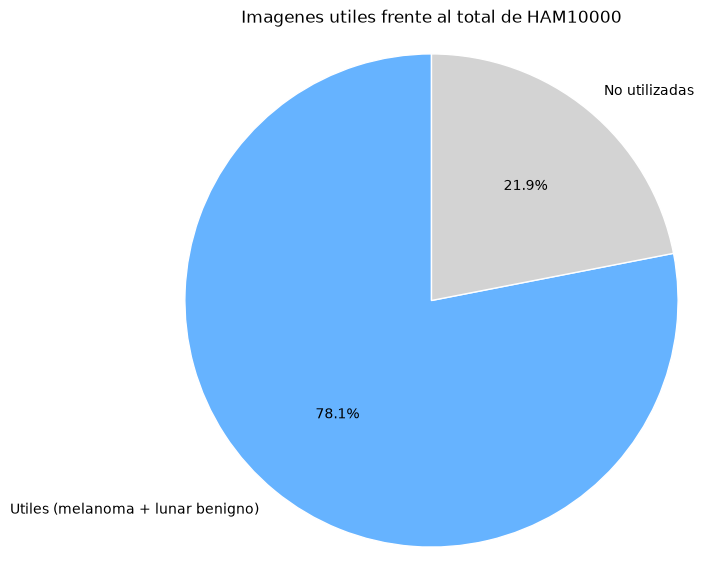

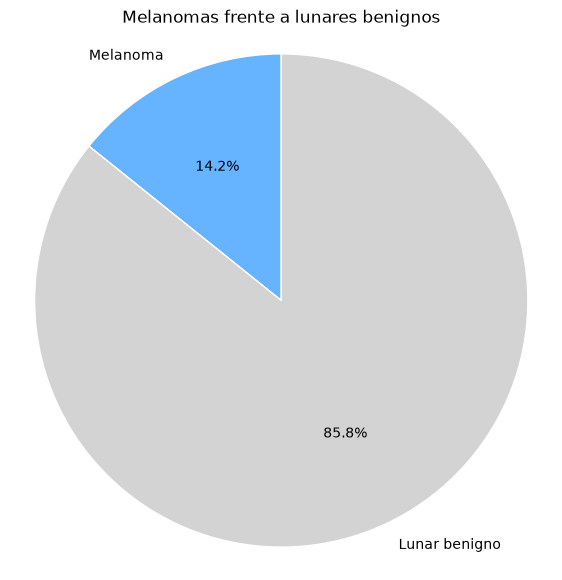

Cantidad por diagnostico:
dx
lunar benigno    6705
melanoma         1113
Name: count, dtype: int64


In [13]:
# Sabemos que los lunares son "nv" y los melanomas son "mel"
etiquetas_utiles = ["nv", "mel"]
df_melanomas = df[df["dx"] == "mel"].copy()
df_filtrado = df[df["dx"].isin(etiquetas_utiles)].copy()


imagenes_totales = df["image_id"].nunique()
imagenes_utiles = df_filtrado["image_id"].nunique()
imagenes_no_utilizadas = imagenes_totales - imagenes_utiles

print(f"Imagenes totales: {imagenes_totales}")
print(f"Imagenes utiles (melanoma + lunar benigno): {imagenes_utiles}")
print(f"Imagenes no utilizadas: {imagenes_no_utilizadas}")



#Plot de imagenes utiles frente al total de HAM10000
conteo_filtro = [imagenes_utiles, imagenes_no_utilizadas]
plt.figure(figsize=(7, 7))
plt.pie(
    conteo_filtro,
    labels=["Utiles (melanoma + lunar benigno)", "No utilizadas"],
    autopct="%1.1f%%",
    startangle=90,
    colors=["#66b3ff", "#d3d3d3"],
    wedgeprops={"edgecolor": "white"},
)
plt.title("Imagenes utiles frente al total de HAM10000")
plt.axis("equal")
plt.show()


#Plot de melanomas frente a lunares benignos
conteo_malignos = [df_melanomas.shape[0], df_filtrado.shape[0] - df_melanomas.shape[0]]
plt.figure(figsize=(7, 7))
plt.pie(
    conteo_malignos,
    labels=["Melanoma", "Lunar benigno"],
    autopct="%1.1f%%",
    startangle=90,
    colors=["#66b3ff", "#d3d3d3"],
    wedgeprops={"edgecolor": "white"},
)
plt.title("Melanomas frente a lunares benignos")
plt.axis("equal")
plt.show()


print("Cantidad por diagnostico:")
print(df_filtrado["dx"].value_counts().rename(index={"nv": "lunar benigno", "mel": "melanoma"}))


Vemos que existe una gran diferencia entre la cantidad de lunares benignos y melanomas por lo que deberemos de balancearlos.

## 4. Una imagen por lesion y balanceo

Despues de ver el total de imagenes utiles, conservamos una imagen por `lesion_id` para evitar fuga de datos y balanceamos las clases.

In [14]:
semilla = 42
df_unico = (
    df_filtrado.groupby("lesion_id", group_keys=False)
    .sample(n=1, random_state=semilla)
    .reset_index(drop=True)
)

cantidad_por_clase = int(df_unico["dx"].value_counts().min())
df_balanceado = (
    df_unico.groupby("dx", group_keys=False)
    .sample(n=cantidad_por_clase, random_state=semilla)
    .reset_index(drop=True)
)

print("Lesiones con una imagen:", len(df_unico))
print("Imagenes despues del balanceo:", len(df_balanceado))
print("Cantidad balanceada por clase:")
print(df_balanceado["dx"].value_counts().rename(index={"nv": "lunar benigno", "mel": "melanoma"}))


Lesiones con una imagen: 6017
Imagenes despues del balanceo: 1228
Cantidad balanceada por clase:
dx
melanoma         614
lunar benigno    614
Name: count, dtype: int64


Guardamos las imagenes del conjunto balanceado en una carpeta nueva para conservar intacto el conjunto procesado anterior.

In [15]:
from pathlib import Path
import shutil

carpetas = {"nv": "lunar_benigno", "mel": "melanoma"}
salida = Path("../data/processed")
origen = Path("../data/raw/images")

destino_imgs = salida / "images"
destino_imgs.mkdir(parents=True, exist_ok=True)

df_balanceado = df_balanceado.copy()
df_balanceado["label"] = df_balanceado["dx"].map(carpetas)
df_balanceado["etiqueta"] = (df_balanceado["dx"] == "mel").astype(int)  
df_balanceado.to_csv(salida / "metadata.csv", index=False)

for _, fila in df_balanceado.iterrows():
    imagen = f"{fila['image_id']}.jpg"
    shutil.copy2(origen / imagen, destino_imgs / imagen)

print("Datos guardados en", destino_imgs)

Datos guardados en ..\data\processed\images
